In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from scipy.optimize import fsolve

# 1. Data Initialization
t = np.array([0, 2, 4, 6, 8, 10, 12], dtype=float)
T = np.array([5.2, 6.4, 7.9, 9.5, 10.1, 9.3, 7.6], dtype=float)
n = len(t)
h = 2.0

# 2. Difference Table Generation
diff_table = np.zeros((n, n))
diff_table[:, 0] = T
for j in range(1, n):
    for i in range(n - j):
        diff_table[i, j] = diff_table[i+1, j-1] - diff_table[i, j-1]

columns = ['T'] + [f'Δ^{i}T' for i in range(1, n)]
df_diff = pd.DataFrame(diff_table, index=t, columns=columns)
df_diff = df_diff.replace(0.0, np.nan).dropna(how='all', axis=1)

print("Difference Table:")
print(df_diff.round(4).fillna(''))

Difference Table:
         T Δ^1T Δ^2T Δ^3T Δ^4T Δ^5T Δ^6T
0.0    5.2  1.2  0.3 -0.2 -0.9  1.6 -1.4
2.0    6.4  1.5  0.1 -1.1  0.7  0.2     
4.0    7.9  1.6 -1.0 -0.4  0.9          
6.0    9.5  0.6 -1.4  0.5               
8.0   10.1 -0.8 -0.9                    
10.0   9.3 -1.7                         
12.0   7.6                              


In [2]:
# Function for computing p terms
def p_term(p, n, formula='forward'):
    term = p
    for i in range(1, n):
        if formula == 'forward': term *= (p - i)
        elif formula == 'backward': term *= (p + i)
    import math
    return term / math.factorial(n)

# Bessel's Formula for t=5.0 (t0=4, index 2)
p_5 = (5.0 - 4.0) / h
T_5 = (T[2] + T[3])/2 + (p_5 - 0.5)*diff_table[2, 1] + \
      (p_5*(p_5 - 1)/2) * ((diff_table[1, 2] + diff_table[2, 2])/2) + \
      ((p_5 - 0.5)*p_5*(p_5 - 1)/6) * diff_table[1, 3]

# Stirling's Formula for t=6.4 (t0=6, index 3)
p_64 = (6.4 - 6.0) / h
T_64_stirling = T[3] + p_64 * ((diff_table[3, 1] + diff_table[2, 1])/2) + \
                (p_64**2 / 2) * diff_table[2, 2] + \
                (p_64 * (p_64**2 - 1) / 6) * ((diff_table[2, 3] + diff_table[1, 3])/2) + \
                (p_64**2 * (p_64**2 - 1) / 24) * diff_table[1, 4]

# Newton Backward for t=11.0 (tn=12, index 6)
p_11 = (11.0 - 12.0) / h
T_11 = T[6] + p_11*diff_table[5, 1] + (p_11*(p_11+1)/2)*diff_table[4, 2] + \
       (p_11*(p_11+1)*(p_11+2)/6)*diff_table[3, 3]

print(f"Estimate at t=5.0 (Bessel): {T_5:.4f}°C")
print(f"Estimate at t=6.4 (Stirling): {T_64_stirling:.4f}°C")
print(f"Estimate at t=11.0 (Newton Backward): {T_11:.4f}°C")

Estimate at t=5.0 (Bessel): 8.7562°C
Estimate at t=6.4 (Stirling): 9.7229°C
Estimate at t=11.0 (Newton Backward): 8.5312°C



Maximum Temperature:
Time: 7.8448 h
Value: 10.1046°C

Excursion Limits (Threshold > 8.0°C):
Start: 4.1184 h
End: 11.5682 h
Total time above limit: 7.4498 h
Decision: Shipment REJECTED (Total time exceeded threshold limits).


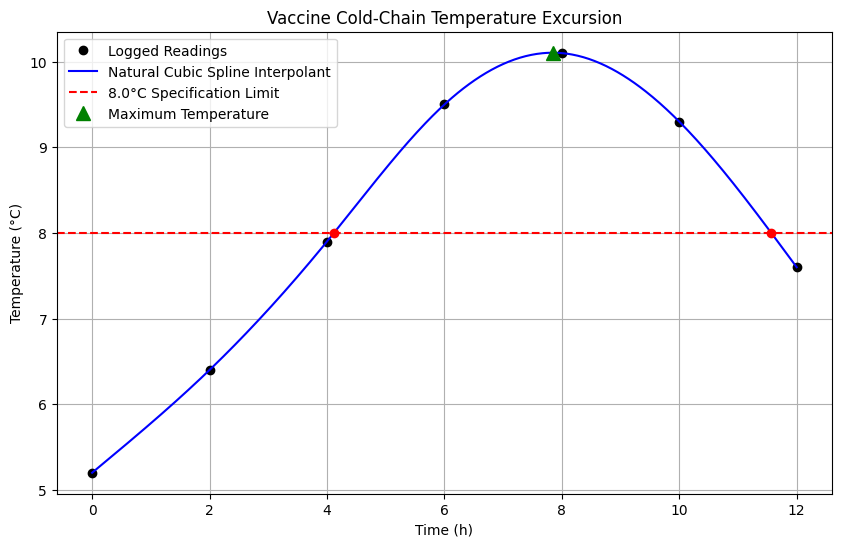

In [4]:
# Finding Maximum logged temperature
# Derivative of spline = 0
roots_deriv = cs.derivative().roots()
valid_roots = [r for r in roots_deriv if 6 <= r <= 10]
t_max = valid_roots[0]
T_max = float(cs(t_max))

print(f"\nMaximum Temperature:")
print(f"Time: {t_max:.4f} h")
print(f"Value: {T_max:.4f}°C")

# Excursion times (Crossing 8.0°C)
def excursion_func(time):
    return cs(time) - 8.0

# Initial guesses based on visual table data (between 4-6, and 10-12)
t_cross_1 = fsolve(excursion_func, 4.5)[0]
t_cross_2 = fsolve(excursion_func, 11.5)[0]
total_time = t_cross_2 - t_cross_1

print(f"\nExcursion Limits (Threshold > 8.0°C):")
print(f"Start: {t_cross_1:.4f} h")
print(f"End: {t_cross_2:.4f} h")
print(f"Total time above limit: {total_time:.4f} h")
if total_time > 0:
    print("Decision: Shipment REJECTED (Total time exceeded threshold limits).")
else:
    print("Decision: Shipment RELEASED.")

# 6. Plotting the results
t_continuous = np.linspace(0, 12, 500)
T_continuous = cs(t_continuous)

plt.figure(figsize=(10, 6))
plt.plot(t, T, 'ko', label='Logged Readings')
plt.plot(t_continuous, T_continuous, 'b-', label='Natural Cubic Spline Interpolant')
plt.axhline(8.0, color='r', linestyle='--', label='8.0°C Specification Limit')
plt.plot([t_cross_1, t_cross_2], [8.0, 8.0], 'ro')
plt.plot(t_max, T_max, 'g^', markersize=10, label='Maximum Temperature')

plt.title('Vaccine Cold-Chain Temperature Excursion')
plt.xlabel('Time (h)')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.grid(True)
plt.show()

In [3]:
# Bessel for t=6.4 (t0=6, index 3)
p_64_b = (6.4 - 6.0) / h
T_64_bessel = (T[3] + T[4])/2 + (p_64_b - 0.5)*diff_table[3, 1] + \
              (p_64_b*(p_64_b - 1)/2) * ((diff_table[2, 2] + diff_table[3, 2])/2) + \
              ((p_64_b - 0.5)*p_64_b*(p_64_b - 1)/6) * diff_table[2, 3]

# Newton Backward for t=6.4 (Using tn=8, index 4 to stay near)
p_64_bw = (6.4 - 8.0) / h
T_64_backward = T[4] + p_64_bw*diff_table[3, 1] + \
                (p_64_bw*(p_64_bw+1)/2)*diff_table[2, 2] + \
                (p_64_bw*(p_64_bw+1)*(p_64_bw+2)/6)*diff_table[1, 3] + \
                (p_64_bw*(p_64_bw+1)*(p_64_bw+2)*(p_64_bw+3)/24)*diff_table[0, 4]

# Natural Cubic Spline
cs = CubicSpline(t, T, bc_type='natural')
T_64_spline = float(cs(6.4))

# Tabulate validation results
val_results = {
    "Stirling": T_64_stirling,
    "Bessel": T_64_bessel,
    "Backward": T_64_backward,
    "Cubic Spline": T_64_spline
}
print("\nValidation at t=6.4:")
for method, val in val_results.items():
    print(f"{method}: {val:.4f}°C")

spread = max(val_results.values()) - min(val_results.values())
print(f"Spread: {spread:.4f}°C")


Validation at t=6.4:
Stirling: 9.7229°C
Bessel: 9.7128°C
Backward: 9.7510°C
Cubic Spline: 9.7275°C
Spread: 0.0382°C


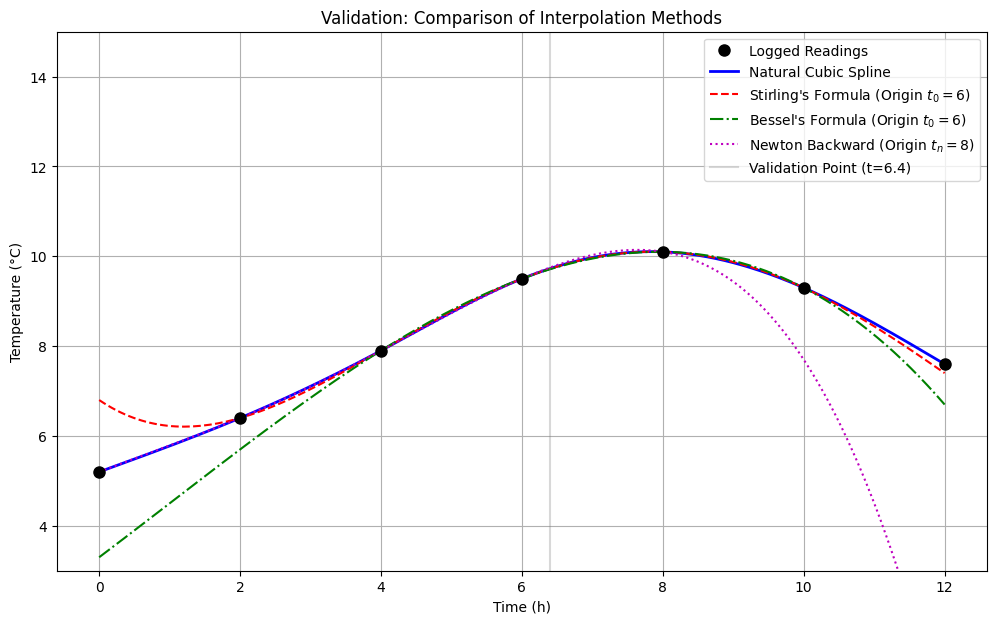

In [5]:
# Generate continuous curves for the 4 validation methods to observe divergence
t_plot = np.linspace(0, 12, 200)
T_stirling_curve = []
T_bessel_curve = []
T_backward_curve = []

for t_val in t_plot:
    # 1. Continuous Stirling (t0=6)
    p = (t_val - 6.0) / h
    stirl = T[3] + p * ((diff_table[3, 1] + diff_table[2, 1])/2) + \
            (p**2 / 2) * diff_table[2, 2] + \
            (p * (p**2 - 1) / 6) * ((diff_table[2, 3] + diff_table[1, 3])/2) + \
            (p**2 * (p**2 - 1) / 24) * diff_table[1, 4]
    T_stirling_curve.append(stirl)

    # 2. Continuous Bessel (t0=6)
    p_b = (t_val - 6.0) / h
    bess = (T[3] + T[4])/2 + (p_b - 0.5)*diff_table[3, 1] + \
           (p_b*(p_b - 1)/2) * ((diff_table[2, 2] + diff_table[3, 2])/2) + \
           ((p_b - 0.5)*p_b*(p_b - 1)/6) * diff_table[2, 3]
    T_bessel_curve.append(bess)

    # 3. Continuous Newton Backward (tn=8)
    p_bw = (t_val - 8.0) / h
    bw = T[4] + p_bw*diff_table[3, 1] + \
         (p_bw*(p_bw+1)/2)*diff_table[2, 2] + \
         (p_bw*(p_bw+1)*(p_bw+2)/6)*diff_table[1, 3] + \
         (p_bw*(p_bw+1)*(p_bw+2)*(p_bw+3)/24)*diff_table[0, 4]
    T_backward_curve.append(bw)

# Plotting all four curves
plt.figure(figsize=(12, 7))
plt.plot(t, T, 'ko', markersize=8, zorder=5, label='Logged Readings')
plt.plot(t_continuous, T_continuous, 'b-', linewidth=2, label='Natural Cubic Spline')
plt.plot(t_plot, T_stirling_curve, 'r--', label="Stirling's Formula (Origin $t_0=6$)")
plt.plot(t_plot, T_bessel_curve, 'g-.', label="Bessel's Formula (Origin $t_0=6$)")
plt.plot(t_plot, T_backward_curve, 'm:', label="Newton Backward (Origin $t_n=8$)")

# Zoom in on the y-axis to see the divergence clearly without breaking the chart
plt.ylim(3, 15)
plt.axvline(6.4, color='gray', linestyle='-', alpha=0.3, label='Validation Point (t=6.4)')

plt.title('Validation: Comparison of Interpolation Methods')
plt.xlabel('Time (h)')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.grid(True)
plt.show()